# Telco churn — exploratory data analysis

Goal: understand **who churns and why** before modelling. Every finding here becomes either an engineered feature, a slice in the error analysis, or a business recommendation.

The production pipeline lives in `src/churn/`; this notebook is for exploration only.

## Setup

In [1]:
import sys
from pathlib import Path

assert sys.version_info >= (3, 10)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from churn.config import load_config
from churn.data import clean, download_data, validate
from churn.features import add_features

SEED = 42
np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
FIG_DIR = ROOT / "results"
FIG_DIR.mkdir(exist_ok=True)

## Load the data

The download is checksum-verified, so this notebook always sees the exact same file.

In [2]:
cfg = load_config(ROOT / "configs/config.yaml")
cfg.data.raw_path = ROOT / cfg.data.raw_path
raw = pd.read_csv(download_data(cfg.data))
print(raw.shape)
raw.head(3)

00:15:29 | INFO | churn.data | Data already at C:\git portfolio\customer-churn-ml\data\raw\telco_churn.csv


(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


## Data quality

`TotalCharges` is read as text. Which rows fail to parse?

In [3]:
bad = pd.to_numeric(raw["TotalCharges"], errors="coerce").isna()
raw.loc[bad, ["tenure", "MonthlyCharges", "TotalCharges"]]

,tenure,MonthlyCharges,TotalCharges
488,0,52.55,
753,0,20.25,
936,0,80.85,
1082,0,25.75,
1340,0,56.05,
3331,0,19.85,
3826,0,25.35,
4380,0,20.00,
5218,0,19.70,
6670,0,73.35,


All of them have `tenure == 0`: brand-new customers who have not been billed. The right fix is **0**, not mean imputation — imputing would invent spend that never happened. `clean()` does exactly that.

In [4]:
df = add_features(clean(raw))
validate(df)
print(f"Rows: {len(df)}  |  churn rate: {df['Churn'].mean():.1%}")
df.isna().sum().sum()

Rows: 7043  |  churn rate: 26.5%


np.int64(0)

## Target balance

~26.5% churn: imbalanced but not extreme. Accuracy would be misleading (predicting 'stay' for everyone scores 73.5%), so we use ROC-AUC, PR-AUC, precision and recall.

## Churn rate by key categorical drivers

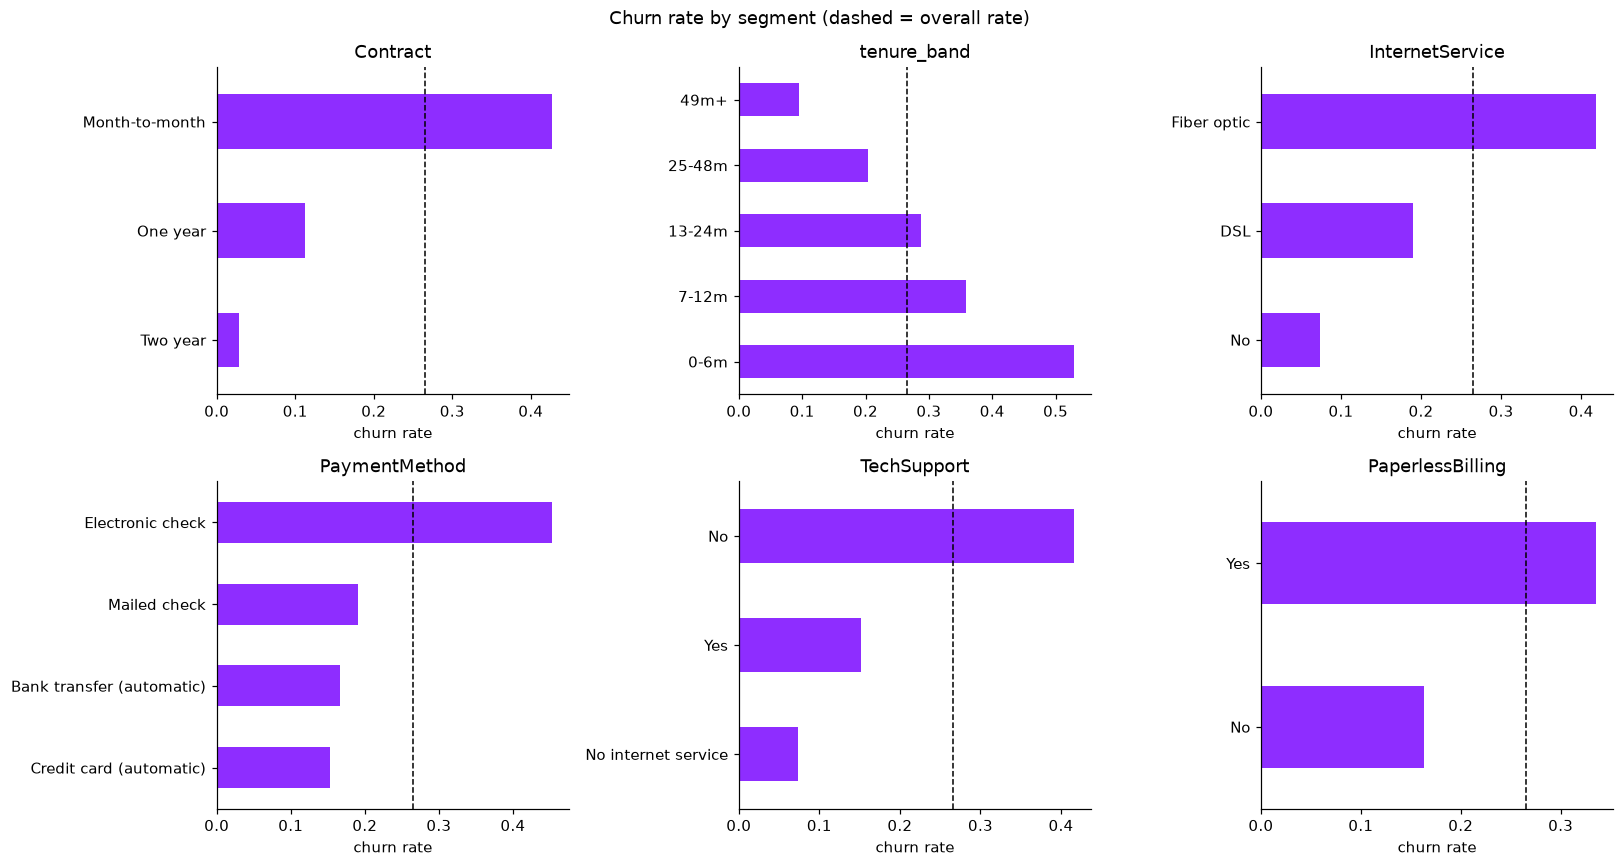

In [5]:
drivers = ["Contract", "tenure_band", "InternetService", "PaymentMethod", "TechSupport", "PaperlessBilling"]
order = {"tenure_band": ["0-6m", "7-12m", "13-24m", "25-48m", "49m+"]}
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), drivers, strict=True):
    rates = df.groupby(col)["Churn"].mean()
    rates = rates.reindex(order[col]) if col in order else rates.sort_values()
    rates.plot.barh(ax=ax, color="#8e2dff")
    ax.axvline(df["Churn"].mean(), color="k", ls="--", lw=1)
    ax.set(title=col, xlabel="churn rate", ylabel="")
fig.suptitle("Churn rate by segment (dashed = overall rate)")
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_churn_drivers.png")
plt.show()

**Findings**

- **Contract** is the strongest single driver: month-to-month churns ~15x more than two-year.
- **Tenure**: over half of customers in their first 6 months churn; risk falls steadily with tenure.
- **Fiber optic** customers churn far more than DSL despite being the premium product — a price/quality signal worth raising with the business.
- **Electronic check** payers churn most; automatic payment acts as a commitment device.
- No **tech support** nearly triples churn (41.6% vs 15.2%): support is a retention lever.

## Numeric features

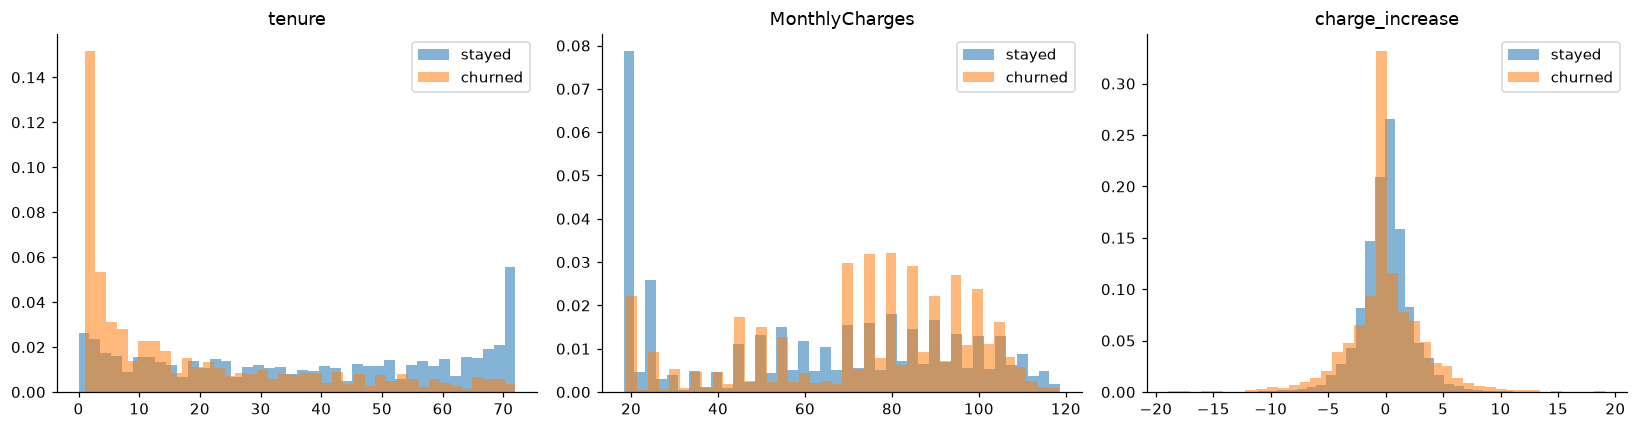

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["tenure", "MonthlyCharges", "charge_increase"], strict=True):
    for label, g in df.groupby("Churn"):
        ax.hist(g[col], bins=40, alpha=0.55, density=True, label="churned" if label else "stayed")
    ax.set(title=col)
    ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_numeric.png")
plt.show()

- Churners are concentrated at **low tenure** and **higher monthly charges** (median $79.6 vs $64.4 for customers who stay).
- `charge_increase` (current bill minus historical average) separates the classes only weakly: price changes are small in this dataset, so it is unlikely to be a top feature.

## Interactions: contract × internet service

In [7]:
pivot = df.pivot_table(index="Contract", columns="InternetService", values="Churn", aggfunc="mean").round(3)
pivot

InternetService,DSL,Fiber optic,No
Contract,,,
Month-to-month,0.322,0.546,0.189
One year,0.093,0.193,0.025
Two year,0.019,0.072,0.008


Month-to-month + fiber is the riskiest combination by far. Long contracts suppress churn even for fiber. Linear models capture these mostly additive effects well, which foreshadows the modelling result (logistic regression is competitive with gradient boosting here).

## Takeaways for modelling

1. Use stratified splits and imbalance-aware metrics.
2. Encode tenure non-linearly (`tenure_band`) and count products (`num_services`).
3. Pick the decision threshold from business costs, not 0.5.
4. In error analysis, slice by contract, tenure and internet service — the model will likely be weakest on the rare churners inside 'safe' groups (long contracts, long tenure).